# 03 · Optimizer study — §3 [15 marks]

The three runs differ **only** in the optimizer: same seed, same initial weights, same data order, same schedule. Run the official pass on the **same machine as notebook 04** — their epoch times are compared in one table.

| | |
|---|---|
| **Owner** | Member 3 |
| **Trains** | `model_b` × SGD, SGD + momentum, Adam |
| **Reads** | the committed split |
| **Writes (official)** | 3 × `history.json` + `test_metrics.json`, curves, `results/figures/optimizer_overlay.png` |
| **Report needs** | chosen optimizer + learning rate and why; comparison against SGD and SGD + momentum; the impact of momentum on convergence **and** final performance |

In [1]:
# ── Cell 1 · Colab bootstrap ─ does nothing when run locally ───────────────
# On a Colab runtime (in the browser, or from VS Code via the Colab extension) it
# clones REPO at BRANCH, installs it, and on every re-run pulls what you pushed since.
# Locally the package is already installed, so this is skipped. Guide: COLAB.md
import importlib.util
import sys

try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False

if IN_COLAB:
    import os
    import subprocess

    def _secret(name, default):  # your Colab Secret if you set one, else the default
        try:
            from google.colab import userdata

            return userdata.get(name) or default
        except Exception:  # not set, or unreadable here (VS Code cannot read Secrets)
            return default

    # The code to run is REPO @ BRANCH. Set your own fork / branch once, in Colab Secrets,
    # as A03_REPO / A03_BRANCH. In VS Code, edit the defaults below for the session and
    # put them back before committing. See COLAB.md.
    REPO = _secret("A03_REPO", "ThejithaR/EN3150-Assignment-03-CNN")
    BRANCH = _secret("A03_BRANCH", "main")
    REPO_DIR = "/content/en3150-a03"

    def _git(*args):  # never prompts: a failure shows as an error, not a hang
        subprocess.run(["git", *args], check=True, env={**os.environ, "GIT_TERMINAL_PROMPT": "0"})

    url = f"https://github.com/{REPO}.git"
    if not os.path.exists(REPO_DIR):
        _git("clone", "--quiet", "--branch", BRANCH, url, REPO_DIR)
    else:  # re-running this cell picks up everything pushed since
        _git("-C", REPO_DIR, "remote", "set-url", "origin", url)
        _git("-C", REPO_DIR, "fetch", "--quiet", "--prune", "origin")
        _git("-C", REPO_DIR, "checkout", "--quiet", "-B", BRANCH, f"origin/{BRANCH}")
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "-e", REPO_DIR], check=True)
    if f"{REPO_DIR}/src" not in sys.path:
        sys.path.insert(0, f"{REPO_DIR}/src")  # an editable install is only seen after a restart
    os.chdir(REPO_DIR)
    _git("log", "--oneline", "-1")  # prints the exact commit this run uses

In [2]:
# ── Cell 2 · Setup ─────────────────────────────────────────────────────────
# %load_ext autoreload
# %autoreload 2

# MODE decides how much runs and whether anything is written:
#   "synthetic"  generated data, 2 epochs, seconds         - before EuroSAT exists
#   "debug"      5% of EuroSAT, 2 epochs                   - find bugs step by step
#   "official"   the full run - the ONLY mode that writes  - then Restart & Run All
MODE = "official"

from edgecnn.config import load_config
from edgecnn.contracts import paths, schema
from edgecnn.data import build_dataloaders
from edgecnn.evaluation import evaluate_run
from edgecnn.evaluation.curves import plot_loss_curves, plot_optimizer_overlay
from edgecnn.models import build_model_from_config
from edgecnn.training import Trainer, summarize_study

In [3]:
# Shared figure style (Member 1): small inline figures, print-quality saved PNGs.
from edgecnn.evaluation.plotting import apply_style

apply_style()

## Config

The study's experiments are listed once, in `configs/stages/training.yaml`; their hyperparameters live in the experiment files.

In [4]:
EXPERIMENTS = load_config("configs/experiments/model_b__adam.yaml").section("optimizer_study")["experiments"]
configs = {name: load_config(f"configs/experiments/{name}.yaml", mode=MODE) for name in EXPERIMENTS}
for name, c in configs.items():
    print(f"{c.run_id:<32} {c.section('optimizer')}  official={c.is_official}")

model_b__sgd__seed42             {'name': 'sgd', 'lr': 0.01, 'momentum': 0.0, 'weight_decay': 0.0001}  official=True
model_b__sgd_momentum__seed42    {'name': 'sgd_momentum', 'lr': 0.01, 'momentum': 0.9, 'nesterov': False, 'weight_decay': 0.0001}  official=True
model_b__adam__seed42            {'name': 'adam', 'lr': 0.001, 'betas': [0.9, 0.999], 'weight_decay': 0.0001}  official=True


## Data — shared by all three runs

In [5]:
data = build_dataloaders(configs[EXPERIMENTS[0]])
results, evaluations = {}, {}
print(data.describe())

100%|██████████| 94.3M/94.3M [00:00<00:00, 110MB/s]


Preparing images:   0%|          | 0/27000 [00:00<?, ?img/s]

Decoding images:   0%|          | 0/27000 [00:00<?, ?img/s]

10 classes, input=(3, 64, 64), seed=42, manifest=split_manifest.csv


## 1 · Plain SGD — `model_b__sgd`

Expect slow, noisy convergence — the baseline.

In [6]:
cfg = configs["model_b__sgd"]
model = build_model_from_config(cfg, data.num_classes)  # seeded: identical start for all three runs
results["sgd"] = Trainer(cfg).fit(model, data, cfg)

model_b__sgd__seed42:   0%|          | 0/30 [00:00<?, ?epoch/s]

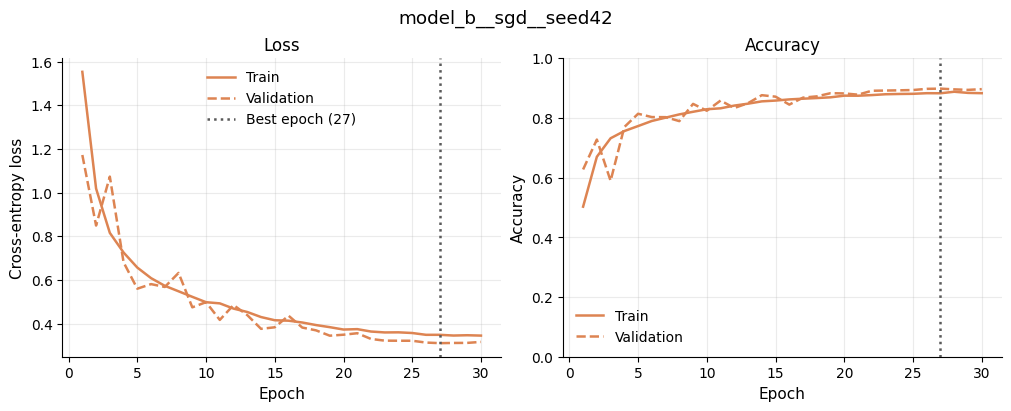

In [7]:
plot_loss_curves(results["sgd"], write=cfg.is_official)

In [8]:
evaluations["sgd"] = evaluate_run(cfg, data, results["sgd"].checkpoint_path)
print(f"test accuracy {evaluations['sgd'].accuracy:.4f}")

test accuracy 0.9025


## 2 · SGD with momentum — `model_b__sgd_momentum`

Only `momentum` differs from run 1. Look for smoother curves and faster early progress.

In [9]:
cfg = configs["model_b__sgd_momentum"]
model = build_model_from_config(cfg, data.num_classes)  # seeded: identical start for all three runs
results["sgd_momentum"] = Trainer(cfg).fit(model, data, cfg)

model_b__sgd_momentum__seed42:   0%|          | 0/30 [00:00<?, ?epoch/s]

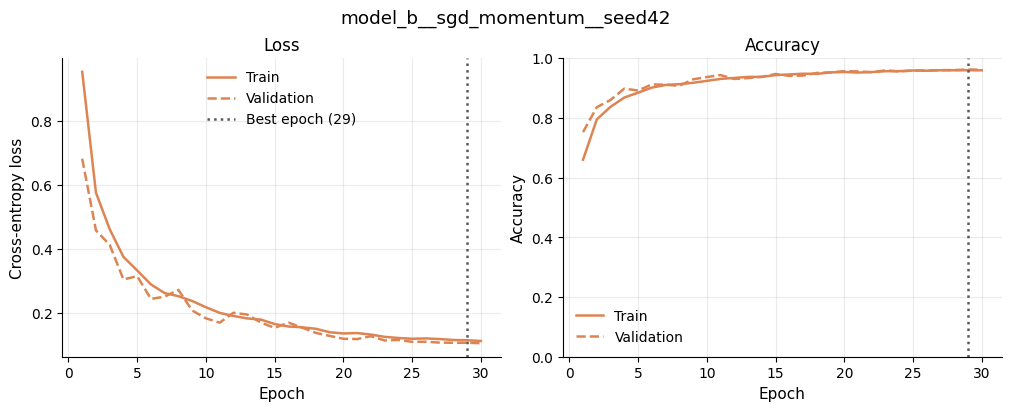

In [10]:
plot_loss_curves(results["sgd_momentum"], write=cfg.is_official)

In [11]:
evaluations["sgd_momentum"] = evaluate_run(cfg, data, results["sgd_momentum"].checkpoint_path)
print(f"test accuracy {evaluations['sgd_momentum'].accuracy:.4f}")

test accuracy 0.9632


## 3 · Adam — the chosen optimizer — `model_b__adam`

Also Model B's headline run, reused by notebooks 04, 06 and 07.

In [12]:
cfg = configs["model_b__adam"]
model = build_model_from_config(cfg, data.num_classes)  # seeded: identical start for all three runs
results["adam"] = Trainer(cfg).fit(model, data, cfg)

model_b__adam__seed42:   0%|          | 0/30 [00:00<?, ?epoch/s]

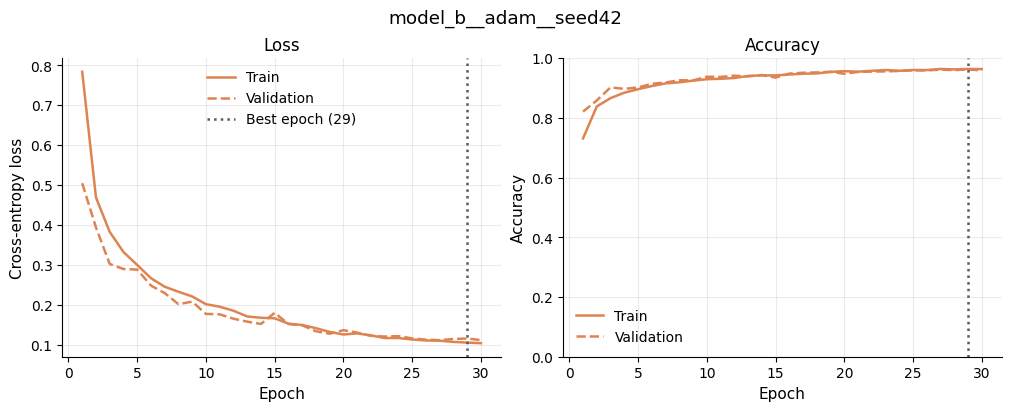

In [13]:
plot_loss_curves(results["adam"], write=cfg.is_official)

In [14]:
evaluations["adam"] = evaluate_run(cfg, data, results["adam"].checkpoint_path)
print(f"test accuracy {evaluations['adam'].accuracy:.4f}")

test accuracy 0.9617


## 4 · All three on one axis

The figure that carries the §3 argument.

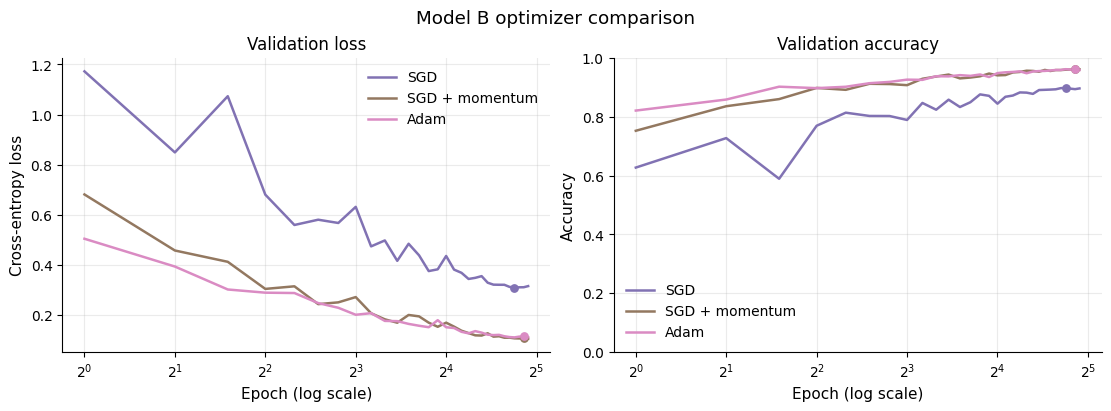

In [15]:
plot_optimizer_overlay(
    [results[key] for key in ("sgd", "sgd_momentum", "adam")],
    write=MODE == "official",
)

## 5 · Summary for the report

In [16]:
summarize_study(results)

{'sgd': {'best_val_acc': 0.8982716049382716,
  'best_epoch': 27,
  'epochs_to_90pct_best': 5,
  'mean_epoch_time_s': 11.4364563536,
  'final_train_val_gap': -0.013580246913580285,
  'final_train_acc': 0.882962962962963,
  'final_val_acc': 0.8965432098765432,
  'epochs_completed': 30},
 'sgd_momentum': {'best_val_acc': 0.9624691358024692,
  'best_epoch': 29,
  'epochs_to_90pct_best': 4,
  'mean_epoch_time_s': 11.046445143100009,
  'final_train_val_gap': -0.0018518518518518823,
  'final_train_acc': 0.9596296296296296,
  'final_val_acc': 0.9614814814814815,
  'epochs_completed': 30},
 'adam': {'best_val_acc': 0.9624691358024692,
  'best_epoch': 29,
  'epochs_to_90pct_best': 3,
  'mean_epoch_time_s': 11.115227741166661,
  'final_train_val_gap': 0.004338624338624308,
  'final_train_acc': 0.9635978835978836,
  'final_val_acc': 0.9592592592592593,
  'epochs_completed': 30}}

## Discussion prompts — §3

- Why Adam, and why this learning rate? (per-parameter steps vs depthwise / pointwise gradient scales)
- Momentum's effect on **convergence speed** — read it off the early epochs.
- Momentum's effect on **final accuracy** — a separate claim; the curves may disagree with the first.
- Cost: Adam keeps two extra state tensors per parameter during training.

## Official-run checklist

- [ ] `MODE = "official"` in the setup cell
- [ ] Kernel → **Restart & Run All** finished without errors
- [ ] every output is what you expect — no stray warnings or giant prints
- [ ] run on the same machine / runtime as notebook 04's official run
- [ ] `pytest tests/contracts` is green
- [ ] commit this notebook **with its outputs**, together with the files it wrote

In [17]:
# ── Colab only: send this run's results back to GitHub ─────────────────────
# Does nothing locally, or in synthetic / debug mode. Guide: COLAB.md
if IN_COLAB and MODE == "official":
    from edgecnn.utils import push_results

    push_results(
        [*(paths.metrics_dir(c.run_id) for c in configs.values()),
         *(paths.figures_dir(c.run_id) for c in configs.values()),
         paths.OPTIMIZER_OVERLAY_PNG],
        "Add optimizer study results (Colab)",
    )

[main 369f9d6] Add optimizer study results (Colab)
 6 files changed, 96 insertions(+), 96 deletions(-)
Current branch main is up to date.
From https://github.com/ThejithaR/EN3150-Assignment-03-CNN
 * branch            main       -> FETCH_HEAD
To https://github.com/ThejithaR/EN3150-Assignment-03-CNN.git
   b81d608..369f9d6  HEAD -> main
Results pushed to 'main'.
Now save the notebook itself: File > Save a copy in GitHub, same branch and same path, so its outputs land too.
